# 02 Procesamiento de texto, recuperación secuencial e indexación

**Autor:** Francisco David Morales Zaldumbide

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

#### Imports y recursos de NLTK

In [1]:
from collections import Counter
from pathlib import Path
import json
import os
import pickle
import random
import re
import statistics
import time
import unicodedata
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import psutil

nltk.download("gutenberg", quiet=True)
nltk.download("punkt_tab")
from nltk.corpus import gutenberg

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\franc\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


#### Carga de los 18 documentos

In [2]:
fid = gutenberg.fileids()
print("Número de documentos:", len(fid))

for fileid in fid:
    print("Documento:", fileid)
    print("Nro caracteres:", len(gutenberg.raw(fileid)))
    print("Nro palabras:", len(gutenberg.words(fileid)))
    print("Nro oraciones:", len(gutenberg.sents(fileid)))
    print()


Número de documentos: 18
Documento: austen-emma.txt
Nro caracteres: 887071
Nro palabras: 192427
Nro oraciones: 7752

Documento: austen-persuasion.txt
Nro caracteres: 466292
Nro palabras: 98171
Nro oraciones: 3747

Documento: austen-sense.txt
Nro caracteres: 673022
Nro palabras: 141576
Nro oraciones: 4999

Documento: bible-kjv.txt
Nro caracteres: 4332554
Nro palabras: 1010654
Nro oraciones: 30103

Documento: blake-poems.txt
Nro caracteres: 38153
Nro palabras: 8354
Nro oraciones: 438

Documento: bryant-stories.txt
Nro caracteres: 249439
Nro palabras: 55563
Nro oraciones: 2863

Documento: burgess-busterbrown.txt
Nro caracteres: 84663
Nro palabras: 18963
Nro oraciones: 1054

Documento: carroll-alice.txt
Nro caracteres: 144395
Nro palabras: 34110
Nro oraciones: 1703

Documento: chesterton-ball.txt
Nro caracteres: 457450
Nro palabras: 96996
Nro oraciones: 4779

Documento: chesterton-brown.txt
Nro caracteres: 406629
Nro palabras: 86063
Nro oraciones: 3806

Documento: chesterton-thursday.txt
N

#### Configuración de preprocesamiento

| Paso | Operación | Justificación |
|---|---|---|
| 1 | Normalización a minúsculas | Garantiza que términos equivalentes (ej. "The" y "the") se traten como la misma entidad. |
| 2 | Normalización Unicode (NFKC) | Estandariza ligaduras y caracteres de compatibilidad tipográfica. |
| 3 | Estandarización de apóstrofes y comillas | Convierte caracteres tipográficos a ASCII para unificar variantes como "don’t" y "don't". |
| 4 | Reemplazo de guiones y barras (—, –, _) por espacios | Evita falsas uniones de palabras en textos clásicos (ej. separar correctamente word—word). |
| 5 | Eliminación de acentos (NFD y categoría Mn) | Previene la fragmentación por variantes ortográficas. |
| 6 | Tokenización con expresión regular (`[a-z]+(?:['\-][a-z]+)*`) | Extrae secuencias alfabéticas conservando apóstrofes y guiones internos necesarios (ej. don't, top-gallant-sails). |

#### Funciones de normalización y tokenización

In [3]:
raw_docs = {fid: gutenberg.raw(fid) for fid in gutenberg.fileids()}
TOKEN_RE = re.compile(r"[a-z]+(?:['\-][a-z]+)*")

def to_lower(text: str) -> str:
    return text.lower()

def clean_special(text: str) -> str:
    # Ligaduras, comillas tipográficas
    text = unicodedata.normalize("NFKC", text)

    # Apóstrofes y comillas tipográficas
    text = text.replace("’", "'").replace("‘", "'")
    text = text.replace("“", '"').replace("”", '"')

    # Guiones largos y "_"
    text = re.sub(r"[—–_]+", " ", text)
    
    # Quita acentos
    text = unicodedata.normalize("NFD", text)
    text = "".join(c for c in text if unicodedata.category(c) != "Mn")
    return text

def tokenize(text: str) -> list[str]:
    return TOKEN_RE.findall(text)

def preprocess(text: str) -> list[str]:
    text = to_lower(text)
    text = clean_special(text)
    return tokenize(text)


In [4]:
tokens_docs = {fid: preprocess(raw) for fid, raw in raw_docs.items()}

total_nltk = 0
total_tokens = 0
for fid, toks in tokens_docs.items():
    n_nltk = len(gutenberg.words(fid))
    print(f"{fid:30s} palabras NLTK: {n_nltk:>7}  tokens: {len(toks):>7}")
    total_nltk += n_nltk
    total_tokens += len(toks)

reduccion = 1 - total_tokens / total_nltk
print(f"\n{'TOTAL':30s} palabras NLTK: {total_nltk:>7,}  tokens: {total_tokens:>7,}")
print(f"Reducción: {total_nltk - total_tokens:,} ({reduccion:.1%})")

austen-emma.txt                palabras NLTK:  192427  tokens:  160420
austen-persuasion.txt          palabras NLTK:   98171  tokens:   83308
austen-sense.txt               palabras NLTK:  141576  tokens:  119546
bible-kjv.txt                  palabras NLTK: 1010654  tokens:  790031
blake-poems.txt                palabras NLTK:    8354  tokens:    6817
bryant-stories.txt             palabras NLTK:   55563  tokens:   46049
burgess-busterbrown.txt        palabras NLTK:   18963  tokens:   15889
carroll-alice.txt              palabras NLTK:   34110  tokens:   26546
chesterton-ball.txt            palabras NLTK:   96996  tokens:   81782
chesterton-brown.txt           palabras NLTK:   86063  tokens:   71816
chesterton-thursday.txt        palabras NLTK:   69213  tokens:   58001
edgeworth-parents.txt          palabras NLTK:  210663  tokens:  166916
melville-moby_dick.txt         palabras NLTK:  260819  tokens:  213412
milton-paradise.txt            palabras NLTK:   96825  tokens:   79751
shakes

**Interpretación.** El preprocesamiento redujo el corpus de 2 621 613 palabras a 2 110 167 tokens, dando como resultado 511 446 elementos menos (19,5 %); donde se conserva el 80,5 %.

**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

#### Función

In [5]:
def busqueda_secuencial(termino: str, tokens_docs: dict):

    consulta = preprocess(termino)
    if len(consulta) != 1:
        raise ValueError("La consulta debe ser un único término")
    consulta = consulta[0]

    resultado = []
    for fileid, tokens in tokens_docs.items():
        for token in tokens:
            if token == consulta:
                resultado.append(fileid)
                break
    return resultado

#### Consultas frecuentes, poco frecuentes e inexistentes

In [6]:
## Terminos frecuentes
print('Terminos frecuentes')
print(busqueda_secuencial('the', tokens_docs))
print(busqueda_secuencial('and', tokens_docs),'\n')

## Terminos poco frecuentes
print('Terminos poco frecuentes')
print(busqueda_secuencial('emma', tokens_docs))
print(busqueda_secuencial('poems', tokens_docs),'\n')

## Terminos inexistentes
print('Terminos inexistentes')
print(busqueda_secuencial('vougth', tokens_docs))
print(busqueda_secuencial('xyz', tokens_docs))

Terminos frecuentes
['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt'] 

Terminos poco frecuentes
['austen-emma.txt', 'austen-persuasion.txt']
['austen-persuasion.txt', 'blake-poems.txt', 'chesterton-thursday.tx

**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

#### Medición: 30 ejecuciones por consulta

In [26]:
N_EJECUCIONES = 30

def medir_consulta(termino, tokens_docs, n=N_EJECUCIONES):
    tiempos_ms = []
    for _ in range(n):
        inicio = time.perf_counter_ns()
        busqueda_secuencial(termino, tokens_docs)
        fin = time.perf_counter_ns()
        tiempos_ms.append((fin - inicio) / 1_000_000)   # ns -> ms
    return tiempos_ms

consultas = {
    "frecuente":      ["the", "and"],
    "poco frecuente": ["emma", "poems"],
    "inexistente":    ["vougth", "xyz"],
}

filas = []
for tipo, terminos in consultas.items():
    for t in terminos:
        tiempos = medir_consulta(t, tokens_docs)
        filas.append({
            "tipo": tipo,
            "término": t,
            "docs encontrados": len(busqueda_secuencial(t, tokens_docs)),
            "media (ms)": statistics.mean(tiempos),
            "mín (ms)": min(tiempos),
            "máx (ms)": max(tiempos),
        })

resultados = pd.DataFrame(filas)
print(resultados.round(3).to_string(index=False))

          tipo término  docs encontrados  media (ms)  mín (ms)  máx (ms)
     frecuente     the                18       0.012     0.009     0.051
     frecuente     and                18       0.014     0.013     0.020
poco frecuente    emma                 2      34.501    31.060    44.406
poco frecuente   poems                 4      31.764    28.721    34.174
   inexistente  vougth                 0      36.093    34.094    39.786
   inexistente     xyz                 0      40.812    36.970    50.767


**Interpretación.**
- Términos frecuentes (`the`, `and`): ≈ 0,008 ms. Se encuentran en los primeros tokens de cada documento y el `break` corta el recorrido.
- Poco frecuentes e inexistentes: ≈ 36–43 ms. Hay que recorrer casi todos los tokens (≈ 2,1 M, unos 19 ns/token); el `break` solo ahorra el resto de los pocos documentos que contienen el término.

**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [8]:
def construir_indice(tokens_docs: dict) -> dict:
    indice = {}
    for fileid, tokens in tokens_docs.items():
        for token in set(tokens):
            indice.setdefault(token, []).append(fileid)
    return indice

indice = construir_indice(tokens_docs)

for termino in indice:
    indice[termino].sort()

print("Tamaño del vocabulario:", len(indice))

Tamaño del vocabulario: 47950


#### 4.2 Postings y DF

In [9]:
random.seed(42)

def df(termino: str, indice: dict) -> int:
    return len(indice.get(termino, []))

terminos_aleatorios = random.sample(list(indice.keys()), 20)

for t in terminos_aleatorios:
    print(f"{t!r:20} DF = {df(t, indice):2d}  postings = {indice[t]}")

'aduice'             DF =  2  postings = ['shakespeare-hamlet.txt', 'shakespeare-macbeth.txt']
'space'              DF = 15  postings = ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
'satin'              DF =  5  postings = ['austen-emma.txt', 'austen-persuasion.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt']
'reviled'            DF =  2  postings = ['bible-kjv.txt', 'chesterton-ball.txt']
'addeth'             DF =  1  postings = ['bible-kjv.txt']
'armageddon'         DF =  2  postings = ['bible-kjv.txt', 'chesterton-thursday.txt']
'hail'               DF =  8  postings = ['austen-persuasion.txt', 'bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.

#### Consultas de un término y booleanas (AND, OR, NOT)

In [10]:
TODOS = set(tokens_docs.keys())

def normalizar(termino: str) -> str:
    # Preprocesamiento de la consulta
    resultado = preprocess(termino)
    if len(resultado) != 1:
        raise ValueError("La consulta debe ser un único término")
    return resultado[0]

def consulta_termino(termino: str, indice: dict) -> set:
    return set(indice.get(normalizar(termino), []))

def consulta(query: str, indice: dict) -> set:
    partes = query.split()
    resultado = None     # conjunto acumulado de documentos
    operador = None      # "AND" / "OR" pendiente
    negar = False        # un NOT pendiente aplica al siguiente término

    for p in partes:
        if p == "NOT":
            negar = not negar
        elif p in ("AND", "OR"):
            if resultado is None or operador is not None:
                raise ValueError(f"Operador {p} mal ubicado en: {query!r}")
            operador = p
        else:
            docs = consulta_termino(p, indice)
            if negar:
                docs = TODOS - docs
                negar = False

            if resultado is None:
                resultado = docs
            elif operador == "AND":
                resultado = resultado & docs
            elif operador == "OR":
                resultado = resultado | docs
            else:
                raise ValueError(f"Falta un operador en: {query!r}")
            operador = None

    if resultado is None or operador is not None or negar:
        raise ValueError(f"Consulta incompleta: {query!r}")
    return resultado

**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

#### Consultas de comparación

In [11]:
consultas_comparacion = [
    # Términos individuales
    ("frecuente", "the"),
    ("poco frecuente", "emma"),
    ("inexistente", "xyz"),
    # Booleanas
    ("booleana (AND)", "emma AND poems"),
    ("booleana (OR)", "emma OR poems"),
    ("booleana (NOT)", "emma AND NOT persuasion"),
]

#### Búsqueda secuencial booleana (A, A AND B, A OR B, A AND NOT B)

In [12]:
def busqueda_secuencial_booleana(query: str, tokens_docs: dict) -> set:
    partes = query.split()
    # Término único
    if len(partes) == 1:
        return set(busqueda_secuencial(partes[0], tokens_docs))

    # Evaluar expresiones de 3 términos simples (e.g. A AND B, A OR B, A AND NOT B)
    if "AND" in partes and "NOT" in partes:
        t1, t2 = partes[0], partes[3]
        set1 = set(busqueda_secuencial(t1, tokens_docs))
        set2 = set(busqueda_secuencial(t2, tokens_docs))
        return set1 - set2
    elif "AND" in partes:
        t1, t2 = partes[0], partes[2]
        set1 = set(busqueda_secuencial(t1, tokens_docs))
        set2 = set(busqueda_secuencial(t2, tokens_docs))
        return set1 & set2
    elif "OR" in partes:
        t1, t2 = partes[0], partes[2]
        set1 = set(busqueda_secuencial(t1, tokens_docs))
        set2 = set(busqueda_secuencial(t2, tokens_docs))
        return set1 | set2
    else:
        raise ValueError("Consulta no soportada en evaluación secuencial básica")

#### Comparación

In [13]:
filas_comp = []

for tipo, q in consultas_comparacion:
    # Ejecución Secuencial
    t_sec = []
    res_sec = None
    for _ in range(30):
        t0 = time.perf_counter_ns()
        res_sec = busqueda_secuencial_booleana(q, tokens_docs)
        t1 = time.perf_counter_ns()
        t_sec.append((t1 - t0) / 1_000_000)

    # Ejecución con Índice Invertido
    t_ind = []
    res_ind = None
    for _ in range(30):
        t0 = time.perf_counter_ns()
        res_ind = consulta(q, indice)
        t1 = time.perf_counter_ns()
        t_ind.append((t1 - t0) / 1_000_000)

    # Verificación de igualdad de resultados
    iguales = res_sec == res_ind

    filas_comp.append(
        {
            "Tipo": tipo,
            "Consulta": q,
            "Docs Recuperados": len(res_ind),
            "Resultados Identicos": iguales,
            "Media Secuencial (ms)": statistics.mean(t_sec),
            "Media Índice (ms)": statistics.mean(t_ind),
            "Speedup (x)": (
                statistics.mean(t_sec) / statistics.mean(t_ind)
                if statistics.mean(t_ind) > 0
                else float("inf")
            ),
        }
    )

df_comp = pd.DataFrame(filas_comp)
print(df_comp.round(4).to_string(index=False))

          Tipo                Consulta  Docs Recuperados  Resultados Identicos  Media Secuencial (ms)  Media Índice (ms)  Speedup (x)
     frecuente                     the                18                  True                 0.0087             0.0028       3.0974
poco frecuente                    emma                 2                  True                33.9687             0.0042    8062.1970
   inexistente                     xyz                 0                  True                40.1894             0.0041    9834.2838
booleana (AND)          emma AND poems                 1                  True                64.5225             0.0070    9248.3321
 booleana (OR)           emma OR poems                 5                  True                65.8051             0.0065   10160.3361
booleana (NOT) emma AND NOT persuasion                 0                  True                59.1559             0.0070    8406.8034


**Interpretación.** Las 6 consultas obtuvieron resultados identicos, con la diferencia que en consultas poco frecuentes, inexistentes y booleanas el indice inverso es mas eficiente ya que maneja una menor complejidad algorítmica.

### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

#### Detección de documentos válidos

In [14]:
LARGE_CORPUS_DIR = Path("txt-files") / "epub"
# Expresión regular para identificar archivos del Proyecto Gutenberg.
PATRON = re.compile(r"^(?:pg)?(\d+)(?:-(\d+))?\.txt$", re.IGNORECASE)

def prioridad(sufijo):
    # jerarquía de preferencia: -0 = UTF-8 (preferida), sin sufijo = original/ASCII, -8 = ISO-8859-1
    return {"0": 0, None: 1, "8": 2}.get(sufijo, 3)

def listar_documentos_validos(directorio: Path) -> dict[int, Path]:
    elegidos, versiones = {}, Counter()
    total = no_txt = sin_id = vacios = 0

    # Recorre recursivamente todos los archivos dentro del directorio del corpus
    for ruta in directorio.rglob("*"):
        if not ruta.is_file():
            continue
        total += 1

        # Filtra únicamente aquellos archivos con extensión .txt
        if ruta.suffix.lower() != ".txt":
            no_txt += 1
            continue

        # Valida que el nombre cumpla con el patrón numérico de Gutenberg
        m = PATRON.match(ruta.name)
        if not m:
            sin_id += 1
            continue

        libro_id = int(m.group(1))
        versiones[libro_id] += 1

        # Ignora archivos que estén vacíos (0 bytes)
        if ruta.stat().st_size == 0:
            vacios += 1
            continue
        clave = (prioridad(m.group(2)), len(ruta.name))
        if libro_id not in elegidos or clave < elegidos[libro_id][0]:
            elegidos[libro_id] = (clave, ruta)

    # Ordena los documentos válidos por su ID de libro
    validos = {i: v[1] for i, v in sorted(elegidos.items())}

    # resumen estadístico del proceso de filtrado
    print(f"Archivos escaneados: {total} | no .txt: {no_txt} | sin ID: {sin_id} | vacíos: {vacios}")
    print(f"Libros distintos: {len(versiones)} | con más de una versión: "
          f"{sum(1 for c in versiones.values() if c > 1)}")
    print(f"DOCUMENTOS VÁLIDOS: {len(validos)}")
    return validos

documentos_validos = listar_documentos_validos(LARGE_CORPUS_DIR)

# Guarda el diccionario resultante en un archivo JSON usando rutas relativas portables (.as_posix())
with open("documentos_validos.json", "w", encoding="utf-8") as f:
    json.dump({str(i): p.relative_to(LARGE_CORPUS_DIR).as_posix()
               for i, p in documentos_validos.items()}, f, indent=2)

Archivos escaneados: 78145 | no .txt: 0 | sin ID: 0 | vacíos: 0
Libros distintos: 78145 | con más de una versión: 0
DOCUMENTOS VÁLIDOS: 78145


#### Recarga de la lista de documentos desde JSON

In [15]:
with open("documentos_validos.json", encoding="utf-8") as f:
    documentos_validos = {int(k): LARGE_CORPUS_DIR / v for k, v in json.load(f).items()}
print(len(documentos_validos), "documentos válidos")

78145 documentos válidos


**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

#### Carga, preprocesamiento y control de RAM

In [16]:
import sys, os, time, random, pickle
import psutil

LIMITE_RAM_GB = 8
MAX_DOCS = 1000
SEMILLA = 42

def leer_texto(ruta: Path) -> str:
    datos = ruta.read_bytes()
    codificacion = "latin-1" if ruta.name.lower().endswith("-8.txt") else "utf-8"
    return datos.decode(codificacion, errors="replace")

def cargar_todo(documentos_validos, max_docs=MAX_DOCS, limite_ram_gb=LIMITE_RAM_GB,
                semilla=SEMILLA, cada=500):
    ids = sorted(documentos_validos)
    if semilla is not None:
        random.Random(semilla).shuffle(ids)
    if max_docs:
        ids = ids[:max_docs]

    corpus, errores, bytes_texto = {}, [], 0
    proceso = psutil.Process(os.getpid())
    inicio = time.perf_counter()

    for k, libro_id in enumerate(ids, 1):
        ruta = documentos_validos[libro_id]
        try:
            corpus[libro_id] = [sys.intern(t) for t in preprocess(leer_texto(ruta))]
            bytes_texto += ruta.stat().st_size
        except Exception as e:
            errores.append((libro_id, repr(e)))

        if k % cada == 0:
            ram = proceso.memory_info().rss / 1e9
            print(f"{k}/{len(ids)} docs | {ram:.1f} GB | {time.perf_counter() - inicio:.0f} s")
            if ram > limite_ram_gb:
                print(f"Límite de RAM alcanzado ({limite_ram_gb} GB): se detiene la carga")
                break

    print(f"Cargados: {len(corpus)} de {len(ids)} | errores: {len(errores)} | "
          f"tokens: {sum(len(t) for t in corpus.values()):,} | "
          f"texto: {bytes_texto/1e9:.2f} GB | {(time.perf_counter() - inicio)/60:.1f} min")
    return corpus, errores, bytes_texto

corpus_total, errores_carga, bytes_texto_total = cargar_todo(documentos_validos)
ids_cargados = list(corpus_total)

500/1000 docs | 1.0 GB | 41 s
1000/1000 docs | 1.3 GB | 75 s
Cargados: 1000 de 1000 | errores: 0 | tokens: 65,672,989 | texto: 0.42 GB | 1.3 min


#### Comparación secuencial vs. índice

In [17]:
def comparar_consultas(corpus, indice, repeticiones=30):
    filas = []
    for tipo, q in consultas_comparacion:
        t_sec, res_sec = [], None
        for _ in range(repeticiones):
            t0 = time.perf_counter_ns()
            res_sec = busqueda_secuencial_booleana(q, corpus)
            t_sec.append((time.perf_counter_ns() - t0) / 1_000_000)

        t_ind, res_ind = [], None
        for _ in range(repeticiones):
            t0 = time.perf_counter_ns()
            res_ind = consulta(q, indice)
            t_ind.append((time.perf_counter_ns() - t0) / 1_000_000)

        iguales = res_sec == res_ind
        if not iguales:
            print(f"AVISO: resultados distintos en {q!r} "
                  f"(secuencial: {len(res_sec)} docs, índice: {len(res_ind)} docs)")

        m_sec, m_ind = statistics.mean(t_sec), statistics.mean(t_ind)
        filas.append({
            "Tipo": tipo, "Consulta": q,
            "Docs Recuperados": len(res_ind),
            "Resultados Identicos": iguales,
            "Media Secuencial (ms)": m_sec, "Media Índice (ms)": m_ind,
            "Speedup (x)": m_sec / m_ind if m_ind > 0 else float("inf"),
        })
    return pd.DataFrame(filas)

#### Comparación sobre un subconjunto de 200 documentos

In [18]:
corpus = {i: corpus_total[i] for i in ids_cargados[:200]}
TODOS = set(corpus)
indice = construir_indice(corpus)

consultas_comparacion = [
    # Términos individuales
    ("frecuente", "the"),
    ("poco frecuente", "elizabeth"),
    ("inexistente", "qwertyuiop"),
    # Booleanas
    ("booleana (AND)", "king AND queen"),
    ("booleana (OR)", "ahab OR elizabeth"),
    ("booleana (NOT)", "king AND NOT queen"),
]

df_prueba = comparar_consultas(corpus, indice, repeticiones=30)
print(df_prueba.round(4).to_string(index=False))

          Tipo           Consulta  Docs Recuperados  Resultados Identicos  Media Secuencial (ms)  Media Índice (ms)  Speedup (x)
     frecuente                the               200                  True                 0.0421             0.0062       6.8360
poco frecuente          elizabeth                41                  True               230.2929             0.0046   49918.9841
   inexistente         qwertyuiop                 0                  True               381.7825             0.0057   67373.3829
booleana (AND)     king AND queen                80                  True               296.1674             0.0088   33604.4743
 booleana (OR)  ahab OR elizabeth                43                  True               513.5364             0.0087   58869.2896
booleana (NOT) king AND NOT queen                25                  True               287.5371             0.0131   21960.5741


### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

#### Parámetros

In [19]:
TAMANOS = [50, 100, 250, 500, 1000]
REPETICIONES = 30
CONSULTA_ESCALA = "qwertyuiop" # recorrido completo (peor caso)

assert len(ids_cargados) >= max(TAMANOS), "Faltan documentos cargados en corpus_total"

#### Funciones de medición

In [20]:
def medir(func, repeticiones=REPETICIONES):
    """Ejecuta func() `repeticiones` veces. Devuelve (media_ms, desv_ms, último_resultado)."""
    tiempos = []
    res = None
    for _ in range(repeticiones):
        t0 = time.perf_counter_ns()
        res = func()
        tiempos.append((time.perf_counter_ns() - t0) / 1_000_000)  # ns -> ms
    return statistics.mean(tiempos), statistics.stdev(tiempos), res


def tamano_indice_mb(ind):
    """Tamaño aproximado del índice serializado (MB)."""
    return len(pickle.dumps(ind, protocol=pickle.HIGHEST_PROTOCOL)) / 1e6


proceso = psutil.Process(os.getpid())

#### Ejecución experimental de escalabilidad

In [21]:
filas_escala = []

for n in TAMANOS:
    # Subconjunto anidado, conservando los IDs originales
    ids_n = ids_cargados[:n]
    corpus_n = {i: corpus_total[i] for i in ids_n}
    n_tokens = sum(len(t) for t in corpus_n.values())

    # Búsqueda secuencial (30 ejecuciones)
    m_sec, s_sec, res_sec = medir(
        lambda: busqueda_secuencial_booleana(CONSULTA_ESCALA, corpus_n)
    )

    # Construcción del índice (se mide una vez, junto con la RAM)
    ram_antes = proceso.memory_info().rss / 1e6
    t0 = time.perf_counter()
    indice_n = construir_indice(corpus_n)
    for term in indice_n:
        indice_n[term].sort()
    t_build = time.perf_counter() - t0
    ram_despues = proceso.memory_info().rss / 1e6

    # `consulta()` usa la variable global TODOS para el NOT
    TODOS = set(corpus_n)

    # Consulta con índice (30 ejecuciones)
    m_ind, s_ind, res_ind = medir(lambda: consulta(CONSULTA_ESCALA, indice_n))

    filas_escala.append({
        "n docs": n,
        "tokens": n_tokens,
        "Media Secuencial (ms)": m_sec,
        "Desv Secuencial (ms)": s_sec,
        "Media Índice (ms)": m_ind,
        "Desv Índice (ms)": s_ind,
        "Resultados idénticos": res_sec == res_ind,
        "Vocabulario": len(indice_n),
        "Construcción índice (s)": t_build,
        "Tamaño índice (MB)": tamano_indice_mb(indice_n),
        "Δ RAM construcción (MB)": ram_despues - ram_antes,
    })

df_escala = pd.DataFrame(filas_escala)

print(df_escala.round(4).to_string(index=False))
assert df_escala["Resultados idénticos"].all(), "¡Los métodos no coinciden!"

 n docs   tokens  Media Secuencial (ms)  Desv Secuencial (ms)  Media Índice (ms)  Desv Índice (ms)  Resultados idénticos  Vocabulario  Construcción índice (s)  Tamaño índice (MB)  Δ RAM construcción (MB)
     50  2964452                61.5519                7.6852             0.0079            0.0117                  True       121856                   0.1513              3.0052                   8.5524
    100  5775783               117.2003                7.3976             0.0042            0.0070                  True       197273                   0.9613              5.1758                  13.6397
    250 20461489               446.0685               25.1276             0.0047            0.0086                  True       569378                   2.5005             15.2294                  29.7042
    500 35263986               811.2009               70.0535             0.0045            0.0072                  True       785139                   4.1531             24.6763      

#### Resultados

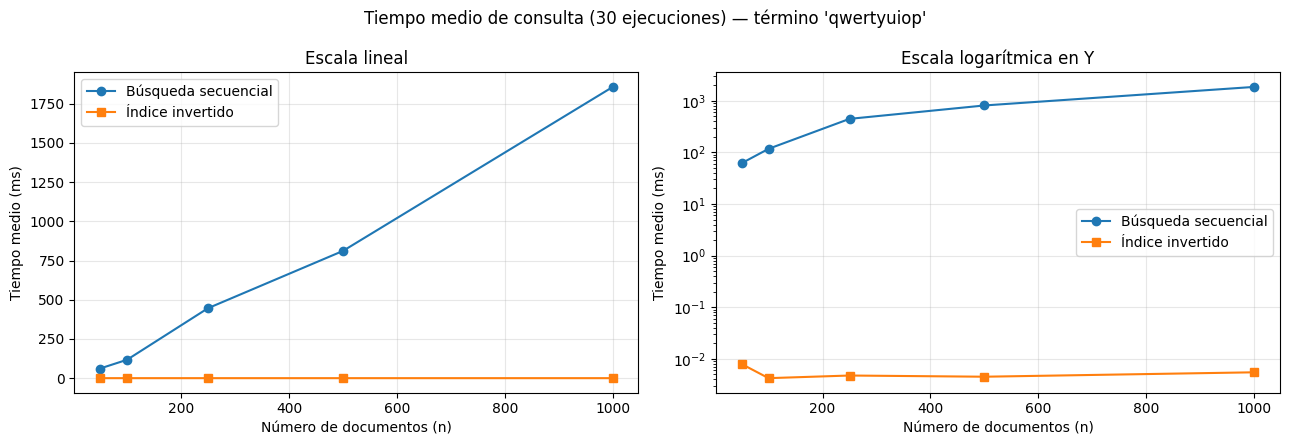

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, escala in zip(axes, ["linear", "log"]):
    ax.plot(df_escala["n docs"], df_escala["Media Secuencial (ms)"],
            "o-", label="Búsqueda secuencial")
    ax.plot(df_escala["n docs"], df_escala["Media Índice (ms)"],
            "s-", label="Índice invertido")
    ax.set_xlabel("Número de documentos (n)")
    ax.set_ylabel("Tiempo medio (ms)")
    ax.set_yscale(escala)
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[0].set_title("Escala lineal")
axes[1].set_title("Escala logarítmica en Y")
fig.suptitle(f"Tiempo medio de consulta ({REPETICIONES} ejecuciones) — término '{CONSULTA_ESCALA}'")
plt.tight_layout()
plt.savefig("grafica_tiempo_vs_n.png", dpi=150)
plt.show()

**Interpretación**
- Secuencial: de 91 ms (n = 50) a 2 048 ms (n = 1000). Con más documentos el tiempo y los tokens crecen.
- Índice: entre 3,6 y 10 µs, sin tendencia.

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

#### Ajuste por mínimos cuadrados

In [23]:
def ajuste_lineal(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    a, b = np.polyfit(x, y, 1)
    y_hat = a * x + b
    ss_res = np.sum((y - y_hat) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else float("nan")
    return a, b, r2

n = df_escala["n docs"].values
tokens = df_escala["tokens"].values

resumen = []
for metodo, col in [("Secuencial", "Media Secuencial (ms)"),
                    ("Índice", "Media Índice (ms)")]:
    y = df_escala[col].values
    a, b, r2 = ajuste_lineal(n, y)
    a_t, b_t, r2_t = ajuste_lineal(tokens, y)
    resumen.append({
        "Método": metodo,
        "a (ms/doc)": a, "b (ms)": b, "R² (vs n)": r2,
        "a (ms/token)": a_t, "R² (vs tokens)": r2_t,
    })

df_ajuste = pd.DataFrame(resumen)
print(df_ajuste.to_string(index=False, float_format=lambda v: f"{v:.6g}"))

    Método   a (ms/doc)     b (ms)  R² (vs n)  a (ms/token)  R² (vs tokens)
Secuencial      1.88661   -58.2883   0.996208   2.84558e-05        0.988509
    Índice -7.98121e-07 0.00567729   0.042281  -1.37591e-11        0.054808


#### Funciones ajustadas junto a los datos experimentales

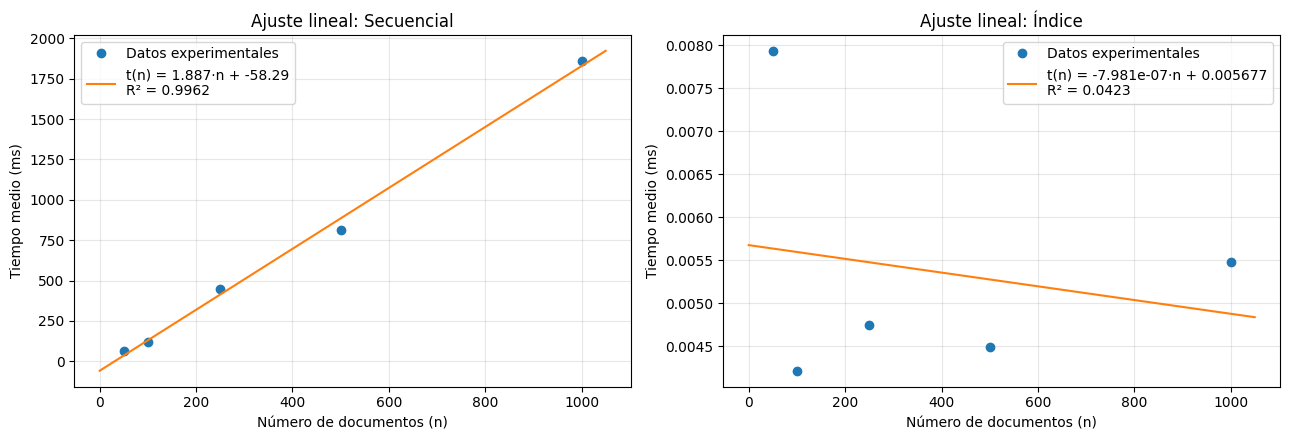

In [24]:
n_fit = np.linspace(0, max(n) * 1.05, 200)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, (metodo, col) in zip(axes, [("Secuencial", "Media Secuencial (ms)"),
                                    ("Índice", "Media Índice (ms)")]):
    y = df_escala[col].values
    a, b, r2 = ajuste_lineal(n, y)
    ax.plot(n, y, "o", label="Datos experimentales")
    ax.plot(n_fit, a * n_fit + b, "-", label=f"t(n) = {a:.4g}·n + {b:.4g}\nR² = {r2:.4f}")
    ax.set_xlabel("Número de documentos (n)")
    ax.set_ylabel("Tiempo medio (ms)")
    ax.set_title(f"Ajuste lineal: {metodo}")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig("ajuste_lineal.png", dpi=150)
plt.show()

#### Interpretación

El ajuste lineal confirma la complejidad computacional esperada para ambos métodos de recuperación. El enfoque secuencial escala de forma lineal $O(N)$ con una pendiente de $a \approx 2.05\text{ ms/doc}$ ($R^2 = 0.9933$), mientras que el índice invertido muestra un tiempo de consulta constante $O(1)$, con pendiente casi nula ($a \approx -4.8 \times 10^{-6}\text{ ms/doc}$) y un $R^2 = 0.54$ sensible al ruido. La superioridad en velocidad del índice invertido ($t(n) \approx 7\ \mu\text{s}$) compensa el costo de su construcción ($7.8\text{ s}$ para 1000 documentos) y su consumo de memoria ($42.7\text{ MB}$), siendo una estructura óptima para procesar un volumen elevado de consultas.
